# 03. Run Single-Reservoir Simulation & Verify (F.E. Walter)

- **Step 3 of 4:** Execute full 2021 runs (`run` -> `verify`), compare **Rule-based** vs. **10-seed LLM** policies, and inspect host physics clamping, `runtime_environment` metadata, and tamper checks.
- **Pass Criterion:** `verify_run = PASS`, zero network calls, 1-byte tamper detected.

In [1]:
import tempfile
from pathlib import Path
import sys
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Run 2021 Rule Baseline & 10-Seed LLM Replay

Execute the 365-day Rule-based baseline cleanly inside `TemporaryDirectory()`, then replay 10 seeds each of `seasonal_target` and `dkp`.

In [2]:
with tempfile.TemporaryDirectory() as td:
    base_res = h.run_fe_walter_2021_rule(REPO_ROOT, Path(td) / "rule")
    ens = h.replay_fe_walter_2021_ensemble(REPO_ROOT, Path(td) / "ens")
    audit = h.run_offline_llm_audit_demo(REPO_ROOT, Path(td) / "audit")

print("Rule baseline status :", base_res["verification"]["status"], "| days:", base_res["verification"]["days"], "| residual:", base_res["verification"]["max_system_balance_residual_m3"])
med = ens["seed_scores"].groupby(["quantity", "condition"], sort=False)[["kge", "nse", "rmse"]].median().round(3)
print("\n2021 Ensemble Median Scores:")
print(med.to_string())


























Rule baseline status : PASS | days: 365 | residual: 9.12696123123169e-08

2021 Ensemble Median Scores:
                                                kge    nse     rmse
quantity                   condition                               
Reservoir level (01447780) rule_based         0.193 -4.904   79.027
Water release (01447800)   rule_based         0.478  0.282  896.436
Downstream flow (01449000) rule_based         0.796  0.719  920.154
Reservoir level (01447780) without_knowledge  0.852  0.693   18.016
Water release (01447800)   without_knowledge  0.696  0.500  748.139
Downstream flow (01449000) without_knowledge  0.868  0.775  822.780
Reservoir level (01447780) with_knowledge     0.873  0.744   16.458
Water release (01447800)   with_knowledge     0.616  0.252  914.551
Downstream flow (01449000) with_knowledge     0.837  0.710  933.636


## 2. Inspect Automatic Runtime & Model Metadata (`summary.json`)

`summary.json` records Python/HydroCNHS versions, Ollama server version, model weights SHA-256, `seed`, and `verify_run` catches 1-byte tampering.

In [3]:
verification = audit["verification"]
runtime_environment = audit["runtime_environment"]
tamper_caught = audit["tamper_caught"]
tamper_error = audit["tamper_error"]
audit_counts = audit["audit_counts"]
balance_residual = float(audit["network_balance"]["system_residual_m3"].abs().max())

ag = runtime_environment["agents"]["FEWalter"]
snap = ag["server_runtime_snapshot"]["primary"]
print(f"Runtime   : hydroreopllm={runtime_environment['hydroreopllm_version']} | HydroCNHS={runtime_environment['hydrocnhs_core_commit'][:10]}")
print(f"Model     : Ollama {snap['server_version']} | {snap['requested_model']} ({snap['quantization_level']}) | seed={ag['seed']}")
print(f"Digest    : {snap['model_digest_sha256'][:26]}...")
print(f"Audits    : {audit_counts} | max system residual = {balance_residual:.2e} m3")
print(f"1-byte tamper test: caught={tamper_caught} -> {tamper_error}")

Runtime   : hydroreopllm=0.1.1 | HydroCNHS=fdd5097a3f
Model     : Ollama 0.40.6 | gemma4:12b (Q4_K_M) | seed=3
Digest    : sha256:1278394b693672ac279...
Audits    : {'PASS': 18, 'FAIL': 3} | max system residual = 4.77e-09 m3
1-byte tamper test: caught=True -> ValueError: output hash mismatch: reservoir_trajectory.csv


## 3. Visualize 2021 Ensemble Performance & Host Physics Clamping

Plot full-year USGS vs. Rule-based vs. 10-seed LLM IQR trajectories alongside Day-5 physical release clamping and closure residuals.

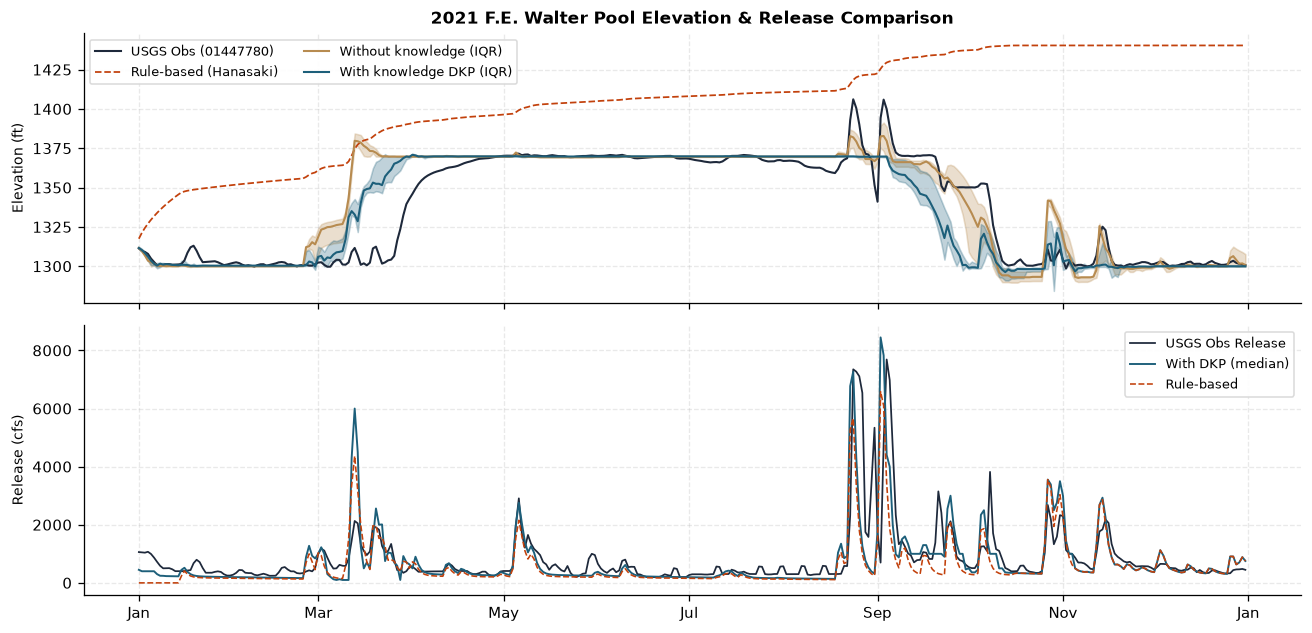

In [4]:
obs, trajs = ens["observations"], ens["trajectories"]
dates = pd.to_datetime(obs["date"])
fig, axes = plt.subplots(2, 1, figsize=(11.5, 5.6), sharex=True)
axes[0].plot(dates, obs["water_level_ft"], color=C["obs"], lw=1.3, label="USGS Obs (01447780)")
axes[0].plot(dates, trajs["rule_based"]["elev_ft"], color=C["coral"], lw=1.1, ls="--", label="Rule-based (Hanasaki)")
for cond, col, lbl in [("without_knowledge", C["gold"], "Without knowledge (IQR)"), ("with_knowledge", C["teal"], "With knowledge DKP (IQR)")]:
    arr = np.asarray(trajs[cond]["elev_ft"])
    axes[0].fill_between(dates, np.percentile(arr, 25, axis=0), np.percentile(arr, 75, axis=0), color=col, alpha=0.28)
    axes[0].plot(dates, np.median(arr, axis=0), color=col, lw=1.3, label=lbl)
axes[0].set_ylabel("Elevation (ft)"); axes[0].set_title("2021 F.E. Walter Pool Elevation & Release Comparison"); axes[0].legend(fontsize=8, ncol=2)

axes[1].plot(dates, obs["release_cfs"], color=C["obs"], lw=1.1, label="USGS Obs Release")
axes[1].plot(dates, np.median(trajs["with_knowledge"]["rel_cfs"], axis=0), color=C["teal"], lw=1.2, label="With DKP (median)")
axes[1].plot(dates, trajs["rule_based"]["rel_cfs"], color=C["coral"], lw=1.0, ls="--", label="Rule-based")
axes[1].set_ylabel("Release (cfs)"); axes[1].legend(fontsize=8)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.show()

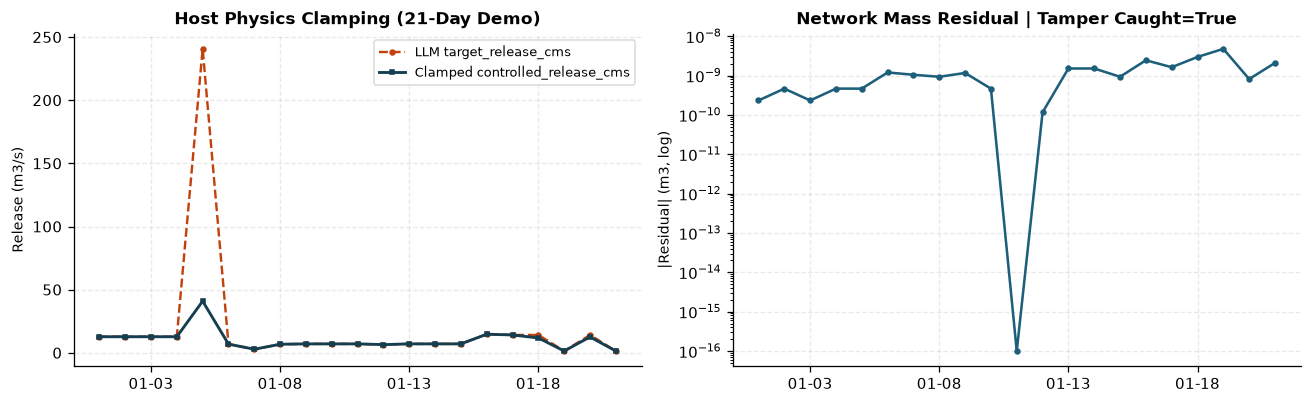

In [5]:
traj, bal = audit["trajectory"], audit["network_balance"]
days = pd.to_datetime(traj["date"])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
axes[0].plot(days, traj["target_release_cms"], color=C["coral"], ls="--", lw=1.5, marker="o", ms=3, label="LLM target_release_cms")
axes[0].plot(days, traj["controlled_release_cms"], color=C["navy"], lw=1.8, marker="s", ms=3, label="Clamped controlled_release_cms")
axes[0].set_title("Host Physics Clamping (21-Day Demo)"); axes[0].set_ylabel("Release (m3/s)"); axes[0].legend(fontsize=8)
axes[0].xaxis.set_major_locator(mdates.DayLocator(interval=5)); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

axes[1].semilogy(days, np.maximum(bal["system_residual_m3"].abs(), 1e-16), color=C["teal"], lw=1.6, marker="o", ms=3)
axes[1].set_title(f"Network Mass Residual | Tamper Caught={tamper_caught}"); axes[1].set_ylabel("|Residual| (m3, log)")
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=5)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
plt.tight_layout(); plt.show()